# 18.1 Introduction to Gaussian Processes (GP)
Any model that is *linear in its parameters* with a Gaussian distribution *over the parameters* is a GP.\
So, BLR is a GP.

### What is a GP?

A GP specifies a collection of function values $f(x_1), ..., f(x_n)$ indexed by inputs $x_1, ..., x_n$ with a joint multivariate Gaussian distribution. The mean vector $\bf \mu$ of the distribution is given by a ***mean function***, typically assumed to be constant or zero, and the covariance matrix is a symmetric $[n, \ n]$ matrix of ***kernel functions*** evaluated at pairs of the inputs $x$:
$$\begin{bmatrix} f(x) \\ f(x_1) \\ \vdots \\ f(x_n) \end{bmatrix} \sim \mathcal{N} \big(\mathbf{\mu}, \mathbf{K}(x)\big)$$
Where $\mathbf{K}_{i, j} = k(x_i, x_j)$; i.e., each element $(i, j)$ of the covariance matrix is the kernel function evaluated at $(x_i, x_j)$.

**The Kernel Function**\
The "kernel function" specifies the covariance between function values evaluated at different inputs.\
We can choose different forms of the kernel function. A common one is the ***Radial Basis Function*** (RBF) defined as:
$$k_\text{RBF}(x, x') = \text{Cov}(f(x), f(x')) = a^2 \exp\big(-\frac{1}{2l^2} \|x - x' \|^2\big)$$
Where $a$ and $l$ are tunable hyperparameters. $a$ is called the *amplitude* parameter because increasing it increases the vertical scale of $f(\cdot)$ while $l$ is called the *length* parameter because higher $l$ increases the wavelength of $f(\cdot)$ (and decreases its frequency).

**Priors and Posteriors**\
The multivariate Gaussian above defines a prior distribution over vectors of observed function outputs. Our posterior then defines the distribution of functions given the observed vector of function outputs.
$$
\begin{align*}
& \text{Prior: } \{f(x_1), ..., f(x_n)\} \sim \mathcal{N}\big(\mu, \mathbf{K}(x)\big) \\ \ \\
& \text{Posterior: } f(x) | f(x_1), ..., f(x_n) \sim \mathcal{N}(m, s^2)
\end{align*}
$$
Where
$$
m = k(x, x_{1:n})\mathbf{K}(x_{1:n})^{-1}f(x_{1:n}) \\
s^2 = k(x, x) - k(x, x_{1:n})\mathbf{K}(x_{1:n})^{-1} k(x, x_{1:n})
$$

These expressions for $m$ and $s^2$ are a bit tricky. $k(x, x_{1:n})$ is a $1 \times n$ vector formed by evaluating $k(x, x_i)$ for $i = 1, ..., n$.\
$m$ is then the expected value of $f(x)$ for any $x$; thus it gives a point prediction for each $x$. While $s^2$ quanitifies the uncertainty around each point prediction.

From the [text](https://d2l.ai/chapter_gaussian-processes/gp-intro.html):
> In typical machine learning, we specify a function with some free parameters (such as a neural network and its weights), and we focus on estimating those parameters, which may not be interpretable. With a Gaussian process, we instead reason about distributions over functions directly ... \
A Gaussian process represents a distribution over functions by specifying a multivariate normal (Gaussian) distribution over all possible function values. \
... if we observe a set of points, then we can condition on these points and infer a distribution over what the value of the function might look like at any other input.

# 18.2 GP Priors

In [1]:
import numpy as np
from scipy.spatial import distance_matrix
import matplotlib.pyplot as plt
import seaborn as sns

### 18.2.1 Definition

> A Gaussian process is defined as a collection of random variables, any finite number of which have a joint Gaussian distribution.

This is a bit cleaner than the definition given in 18.1. Through this lens, a function $f(x)$ is a Gaussian process with ***mean function*** $m(x)$ and ***covariance function*** (kernel) $k(x, x')$. So, $f(x) \sim \mathcal{GP}(m, k)$.

Any collection of function values (outputs) $f(x)$ queried at inputs $x$ has a joint multivariate Gaussian distribution with mean vector $\mu$ and covariance matrix $\mathbf{K}$. Where, $\mu_i = m(x_i)$ and $\mathbf{K}_{ij} = k(x_i, x_j)$. So, any set of function values has the distribution:
$$f(x_1), ..., f(x_n) \sim \mathcal{N}(\mu, \bf K)$$
This is the prior distribution we saw in 18.1.

This definition is a bit abstract. Really, *any function* with the form $$f(x) = w^\intercal \phi(x) = \langle w, \phi(x)\rangle$$ is a GP. Where $w$ has a Gaussian distribution and $\phi$ is any vector of basis functions. This expression is thus a linear combination of basis functions where the coefficients $w$ are drawn from a Gaussian. Moreover, *any GP* $f(x)$ may be *expressed* in this form.

This form $w^\intercal \phi(x)$ is more familiar because it let's us think in terms of the *weight space*. The paradigm of GPs prefers to think in terms of the *function space*. While the two are equivalent (or at least, are in some sense "dual"), operating in the function space has many benefits. Presumably, not least of which is the ability to avoid specifying basis functions...

### 18.2.2 A Simple GP

Let $f(x) = w_0 + w_1 x$ with $w_0, w_1 \sim \mathcal{N}(0, 1)$\
We may express: $$f(x) \;=\; [w_0, w_1] [1, x]^\intercal \;=\; \ w\phi(x)\\ w\coloneqq [w_0, w_1]^\intercal, \ \phi(x) \coloneqq [1, x]^\intercal$$

Because the sum of Gaussians is also Gaussian, $f(x)$ is itself a Gaussian RV, and the joint distribution of any collection of function values $f(x_1), ..., f(x_n)$ is a multivariate Gaussian.
So, $f(x)$ is a GP. It is a *random function*, or a distribution over functions

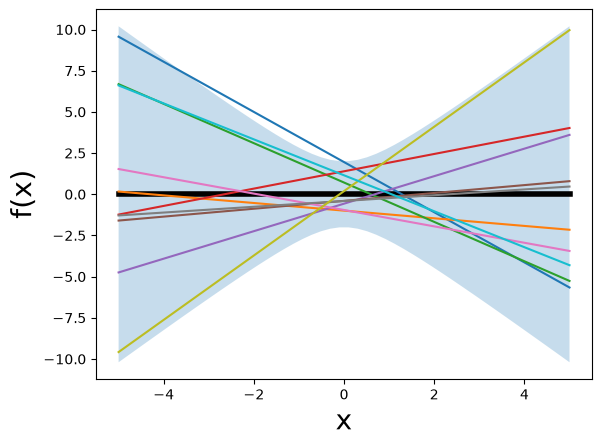

In [2]:
# code from the text -- plotting samples of possible functions
def lin_func(x, n_sample):
    preds = np.zeros((n_sample, x.shape[0]))
    for ii in range(n_sample):
        w = np.random.normal(0, 1, 2)
        y = w[0] + w[1] * x
        preds[ii, :] = y
    return preds

x_points = np.linspace(-5, 5, 50)
outs = lin_func(x_points, 10)
lw_bd = -2 * np.sqrt((1 + x_points ** 2))
up_bd = 2 * np.sqrt((1 + x_points ** 2))

plt.fill_between(x_points, lw_bd, up_bd, alpha=0.25)
plt.plot(x_points, np.zeros(len(x_points)), linewidth=4, color='black')
plt.plot(x_points, outs.T)
plt.xlabel("x", fontsize=20)
plt.ylabel("f(x)", fontsize=20)
plt.show()

### 18.2.3 From weight space to function space

GPs enable us to reason about functions *directly*.

GPs are **defined entirely** by their first two moments; i.e., their mean function and covariance function. So, we can directly specify distributions over potential data-generating functions by defining the Gaussian of the GP; i.e., 
$$f(x_1), ..., f(x_n) \sim \mathcal{N}(\mu, \bf K)$$

Consider the form $f(x) = w^\intercal \phi(x)$, with $w\sim \mathcal{N}(u, S)$. Here:
$$
\begin{align*}
& m(x) \;=\; u^\intercal \phi(x) \\
& k(x, x') \;=\; \phi(x)^\intercal S \phi(x')
\end{align*}
$$
So, $f(x) \sim \mathcal{N}(m(x), \mathbf{\Phi S \Phi^\intercal})$


### 18.2.4 The Radial Basis Function (RBF) Kernel

This is one of the most common choices of covariance function in GPs. As we saw before:
$$k_\text{RBF}(x, x') = \text{Cov}(f(x), f(x')) = a^2 \exp\big(-\frac{1}{2l^2} \|x - x' \|^2\big)$$
Thi covariance function naturally arises when we assume that $f(x)$ is a linear combination $f(x) = w^\intercal \phi(x)$ with $w$ being a vector of Gaussian RVs with length $J$ and $\phi(x)$ being the ***radial basis function***. \
For the $i^{th}$ element of the weights vector:
$$ w_i \sim\mathcal{N}\big(0, \frac{\sigma^2}{J}\big), \ \phi_i(x) = \exp\bigg(-\frac{(x - c_i)^2}{2l^2}\bigg)$$

Then the covariance function for a pair of inputs $(x, x')$ is:
$$k(x, x') = \frac{\sigma^2}{J} \sum_{i = 1}^{J}\phi_i(x)\phi_i(x')$$